
# EMAT 32210: API Data Report
**Author:** Bogdan Gura  
**Date:** October 18, 2026  
**Class:** EMAT 32210 Section 001

## Research Question

Are Bluesky text posts containing at least 200 characters more likely to receive at least 10 likes than posts containing fewer than 200 characters?

## Hypothesis

Posts containing at least 200 characters will have a higher percentage of posts receiving at least 10 likes than shorter posts.

## Theoretical Application

This study explores whether the amount of information in a social media post is associated with audience engagement. Longer posts may provide more context, while shorter posts may be easier to read quickly.

## Statistical Application

Posts will be divided into two length groups and classified as either high-engagement or low-engagement. The percentage of high-engagement posts in each group will be compared using a bar chart.

## Variables

- **Post length:** Number of characters in a post.
- **Long post:** Yes if the post contains at least 200 characters.
- **Like count:** Number of likes received by a post.
- **High engagement:** Yes if the post receives at least 10 likes.

## Academic Honesty & AI Disclosure Statement

As a student in EMAT 32210, I completed the data extraction and core pandas DataFrame manipulation and analysis myself, using the Bluesky API documentation, class provided resources via GitHub, and online searches to resolve syntax questions. I utilized AI tools to assist with configuring the Matplotlib and Seaborn visualization code for plotting, as well as configuring the while loop used to batch API requests and retrieve posts in smaller groups. This assistance helped with graph presentation, axis styling, label annotations, and structuring the request batching process. The remainder of the analysis process was completed by me. I take full responsibility for reviewing, executing, and understanding the code within this notebook. I understand and respect Kent State's EMAT AI policy regarding generative AI usage and attribution, and I have disclosed my use of AI assistance accordingly.

In [18]:
"""
Imports the required libraries and retrieves up to 1000 recent search results from Bluesky. 
The search term "the" is used to find English language posts, 
although it does not guarantee that every result is English.

The while loop collects posts in smaller batches instead of trying to retrieve all 1,000 posts in one large request. 
Bluesky limits how much data can be requested at once for security and service stability, so sending a request that 
is too large may be rejected. The loop requests up to 100 posts at a time and uses a cursor to move to the next batch. 
It continues until it collects enough unique posts or there are no more results available. 
This approach helps avoid oversized requests and allows the notebook to collect a larger dataset gradually.

"""

import requests
import pandas as pd
import matplotlib.pyplot as plt
import time

base = "https://api.bsky.app/xrpc/"
queries = ["technology", "AI", "science", "college", "gaming"]
posts_by_uri = {}

for q in queries:
    cursor = None

    while len(posts_by_uri) < 1000:
        params = {"q": q, "sort": "top", "limit": 100}
        if cursor:
            params["cursor"] = cursor

        r = requests.get(
            base + "app.bsky.feed.searchposts",
            params=params,
            timeout=30
        )
        r.raise_for_status()
        data = r.json()

        for p in data.get("posts", []):
            posts_by_uri[p["uri"]] = p

        cursor = data.get("cursor")
        if not cursor or not data.get("posts"):
            break

        if len(posts_by_uri) >= 1000:
            break

        time.sleep(0.2)

    if len(posts_by_uri) >= 1000:
        break

posts = list(posts_by_uri.values())[:1000]

print("Unique posts collected:", len(posts))
print("Posts with 10+ likes:", sum(
    p.get("likeCount", 0) >= 10 for p in posts
))

Unique posts collected: 1000
Posts with 10+ likes: 562


In [19]:
"""
Uses the getProfiles endpoint to retrieve profile information for up to 25 authors found in the post results. 
It creates a second DataFrame containing author identifiers and follower counts. 
This adds account level context granularity.

"""

authors = list(dict.fromkeys(p["author"]["did"] for p in posts))[:25]

r = requests.get(
    base + "app.bsky.actor.getProfiles",
    params=[("actors", a) for a in authors],
    timeout=30
)
r.raise_for_status()
profiles = r.json()["profiles"]

profile_df = pd.DataFrame([
    {
        "author_did": p["did"],
        "handle": p["handle"],
        "followers": p.get("followersCount")
    }
    for p in profiles
])

profile_df.head()

,author_did,handle,followers
0,did:plc:qnd2lqn52ernybdfonq4mc43,cwarzel.bsky.social,111788
1,did:plc:pdtfdsitjpbwklckuypheuqj,mentha.fun,5802
2,did:plc:sgp3kpycgognnkzg7jxhfzrp,thesgtjoker.bsky.social,85230
3,did:plc:jb2q4yqmgpmefxd4xx66gepm,golikehellmachine.com,44009
4,did:plc:7umvpuxe2vbrc3zrzuquzniu,whstancil.bsky.social,100357


In [20]:

"""

Extracts each post's text, author identifier, and like count into a DataFrame. 
Then it calculates post length and merges the post data with the profile data. 
Finally, it creates the two binary variables needed for my research question.

"""

df = pd.DataFrame([
    {
        "author_did": p["author"]["did"],
        "text": p["record"]["text"],
        "likes": p.get("likeCount", 0)
    }
    for p in posts
    if p.get("record", {}).get("text") is not None
])

df["post_length"] = df["text"].str.len()
df = df.merge(profile_df, on="author_did", how="left")

df["post_type"] = df["post_length"].ge(200).map({
    True: "Long (200+ characters)",
    False: "Short (under 200 characters)"
})

df["high_engagement"] = df["likes"].ge(10)

df[["text", "post_length", "likes", "post_type",
    "high_engagement", "followers"]].head()

,text,post_length,likes,post_type,high_engagement,followers
0,Silicon Valley is a faith-based industry www.t...,76,106,Short (under 200 characters),True,111788.0
1,bike shorts technology🌐,23,72,Short (under 200 characters),True,5802.0
2,Elon Musk is using his monopoly on technology ...,205,289,Long (200+ characters),True,85230.0
3,"in sum, technology is a land of contrasts",41,62,Short (under 200 characters),True,44009.0
4,"Nah, I’m pretty worried about the underlying t...",55,45,Short (under 200 characters),True,100357.0


In [21]:
"""

Groups posts by length and calculates the total number of posts, how many received at least 10 likes, 
and the percentage that reached that threshold. This percentage is the main measure used to measure my hypothesis.

"""

summary = df.groupby("post_type").agg(
    total_posts=("likes", "size"),
    high_engagement_posts=("high_engagement", "sum"),
    engagement_rate=("high_engagement", "mean")
).reset_index()

summary["engagement_rate"] = summary["engagement_rate"] * 100

summary

,post_type,total_posts,high_engagement_posts,engagement_rate
0,Long (200+ characters),310,248,80.000000
1,Short (under 200 characters),690,314,45.507246


In [22]:
print("Number of posts:", len(df))
print("Missing like counts:", df["likes"].isna().sum())
print("Highest like count:", df["likes"].max())
print("Posts with 10+ likes:", (df["likes"] >= 10).sum())

display(df[["text", "post_length", "likes"]].head(10))
display(df["likes"].describe())

Number of posts: 1000
Missing like counts: 0
Highest like count: 5310
Posts with 10+ likes: 562


,text,post_length,likes
0,Silicon Valley is a faith-based industry www.t...,76,106
1,bike shorts technology🌐,23,72
2,Elon Musk is using his monopoly on technology ...,205,289
3,"in sum, technology is a land of contrasts",41,62
4,"Nah, I’m pretty worried about the underlying t...",55,45
5,"When the iPod came out, nobody had to convince...",275,254
6,we straight up no longer have the technology,44,281
7,"""Warp Technology seller, I tell you I am going...",175,27
8,the technology that's losing $80 billion a yea...,92,131
9,A helicopter displaying the potential of VTOL ...,67,71


count    1000.000000
mean       67.549000
std       293.298298
min         1.000000
25%         4.000000
50%        12.000000
75%        38.000000
max      5310.000000
Name: likes, dtype: float64

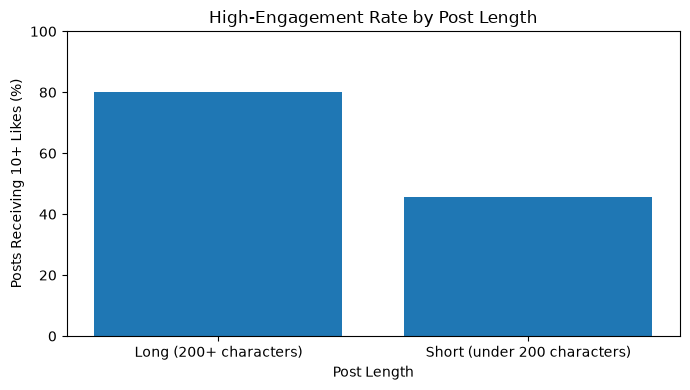

In [23]:
"""

Creates a bar chart comparing the percentage of long 
and short posts that received at least 10 likes. 

"""

plt.figure(figsize=(7, 4))

plt.bar(summary["post_type"], summary["engagement_rate"])

plt.title("High-Engagement Rate by Post Length")
plt.xlabel("Post Length")
plt.ylabel("Posts Receiving 10+ Likes (%)")
plt.ylim(0, 100)
plt.tight_layout()
plt.show()

In [24]:
"""

Compares the two percentages and prints which group had the higher observed engagement rate. 
This is a descriptive conclusion based on collected sample.

"""

rates = summary.set_index("post_type")["engagement_rate"]

long_rate = rates.get("Long (200+ characters)", 0)
short_rate = rates.get("Short (under 200 characters)", 0)

print(f"Long-post engagement rate: {long_rate:.1f}%")
print(f"Short-post engagement rate: {short_rate:.1f}%")

if long_rate > short_rate:
    print("Long posts had the higher observed engagement rate.")
elif long_rate < short_rate:
    print("Short posts had the higher observed engagement rate.")
else:
    print("Both groups had the same observed engagement rate.")

Long-post engagement rate: 80.0%
Short-post engagement rate: 45.5%
Long posts had the higher observed engagement rate.


### Conclusion ###

The results support the research hypothesis within the collected sample. Posts containing at least 200 characters had a high-engagement rate of 80.0%, compared with 45.5% for posts containing fewer than 200 characters. This represents a difference of 34.5 percentage points.

These findings suggest that longer text posts were more likely to receive at least 10 likes in the dataset. However, this relationship does not establish that post length causes higher engagement. Other factors, including author popularity, topic, and post age, may influence the results.

### Limitations and Next Steps ###

The dataset was collected using Bluesky's public search API, which may not return a representative sample of all posts. Search terms and ranking methods may influence which posts are included. Future research could use a broader and more consistent sampling method and examine whether the relationship between post length and engagement remains similar across different topics.